# Degree correlations

**Question:** do users with many links connect to other users with many links (assortative), or to users with few links (disassortative)? And is this more than their degrees alone would force?

The results come from `scripts/degree_correlations.py`. Run `python scripts/reproduce.py` first, or just that script.

## Terms from the course (Chapter 7)

- **Assortativity coefficient $r$**: the correlation between the degrees at the two ends of a link. $r > 0$ is assortative, $r < 0$ disassortative, $r \approx 0$ neutral.
- **Degree correlation function $k_{nn}(k)$**: the average degree of the neighbours of nodes with degree $k$. If it falls as $k$ grows, the network is disassortative; without correlations it is flat at $\langle k^2\rangle / \langle k\rangle$. We fit $k_{nn}(k) \propto k^{\mu}$, where $\mu$ is the **degree correlation exponent**.
- **Structural cutoff $k_s = \sqrt{\langle k\rangle N}$**: in a simple network, hubs above $k_s$ cannot find enough other hubs to link to, so the degrees alone already push $r$ below zero.
- **Degree-preserving randomization**: the same eight rewires as notebook 04, where every user keeps their degree. Because of the structural cutoff, we compare $r$ with these rewires rather than with 0.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

ROOT = Path('..')  # project folder
OUT = ROOT / 'outputs' / 'correlations'

summary = pd.read_csv(OUT / 'correlation_summary.csv').iloc[0]
directed = pd.read_csv(OUT / 'directed_assortativity.csv')
knn = pd.read_csv(OUT / 'knn_by_degree.csv')
rewired = pd.read_csv(OUT / 'rewired_assortativity.csv')

## Result 1: the undirected network

In [2]:
print('Users:', int(summary['nodes']), '  links:', int(summary['edges']))
print('Largest degree k_max:', int(summary['max_degree']))
print('Structural cutoff k_s:', round(summary['structural_cutoff']))
print()
print('Observed r:', round(summary['r_observed'], 4))
print('Rewired r, mean:', round(summary['r_rewired_mean'], 4))
print('Rewired r, range:', round(summary['r_rewired_min'], 4), 'to', round(summary['r_rewired_max'], 4))
print('Observed r below every rewire:', summary['r_observed'] < summary['r_rewired_min'])

Users: 5881   links: 18591
Largest degree k_max: 788
Structural cutoff k_s: 193

Observed r: -0.1449
Rewired r, mean: -0.1144
Rewired r, range: -0.1184 to -0.1122
Observed r below every rewire: True


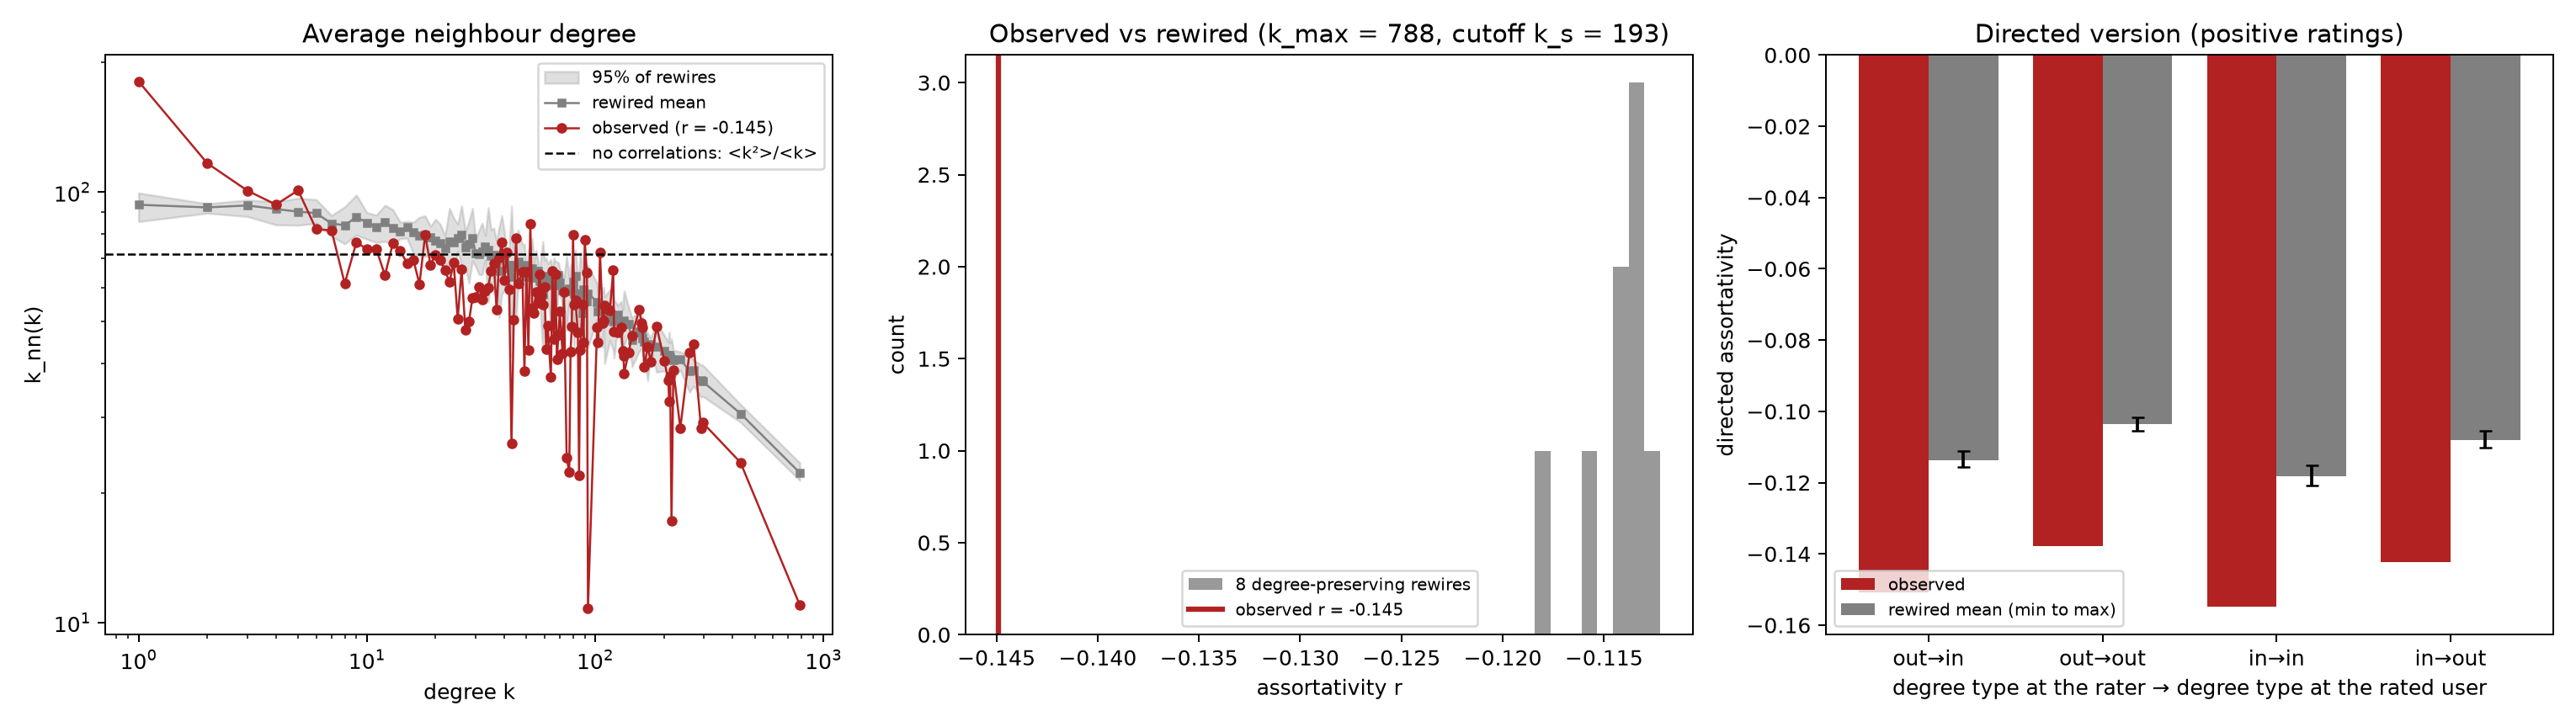

In [3]:
Image(filename=str(OUT / 'degree_correlations.png'))

In [4]:
print('mu, real network:', round(summary['mu_observed'], 3))
print('mu, rewires:', round(summary['mu_rewired_mean'], 3))
knn.head(10).round(2)

mu, real network: -0.225
mu, rewires: -0.104


,degree,users_with_degree,knn_observed,knn_rewired_mean,knn_rewired_p2_5,knn_rewired_p97_5
0,1,2226,180.71,93.42,85.37,99.50
1,2,971,116.63,92.12,89.30,93.93
2,3,552,100.73,93.09,87.71,95.85
3,4,337,93.50,91.31,83.90,94.86
4,5,219,100.92,90.06,83.72,96.79
5,6,179,81.95,89.31,84.59,96.01
6,7,133,81.47,84.54,78.93,88.22
7,8,116,61.31,83.71,75.81,92.42
8,9,86,76.47,87.51,79.48,98.43
9,10,93,73.67,84.90,77.70,89.59


## Result 2: the directed version

Ratings have a direction (rater → rated user), so there are four versions. The label gives the degree type at the rater and at the rated user; for example `out_in` asks whether users who give many ratings rate users who receive many. In these rewires every user keeps both their in-degree and their out-degree.

In [5]:
directed.round(4)

,type,observed,rewired_mean,rewired_std,rewired_min,rewired_max,z_score,outside_rewired_range
0,out_in,-0.1508,-0.1137,0.0015,-0.1157,-0.1111,-24.3985,True
1,out_out,-0.1378,-0.1037,0.0012,-0.1054,-0.1017,-27.8392,True
2,in_in,-0.1549,-0.1182,0.0019,-0.1208,-0.1152,-19.4291,True
3,in_out,-0.1423,-0.1080,0.0015,-0.1101,-0.1055,-22.6035,True


## Findings

1. **The network is disassortative:** $r = -0.145$. Hubs mostly link to users with few links.
2. **Most of this is forced by the degrees.** The largest degree (788) is about four times the structural cutoff (193), and the rewires already give $r \approx -0.114$ (range $-0.118$ to $-0.112$).
3. **The extra $-0.03$ is small but real.** The observed $r$ is below all eight rewires, and each directed version is 0.034–0.037 below its rewires.
4. **Where it comes from.** The 2,226 users with a single link (about 38%) are attached to neighbours with 181 links on average, against 93 after rewiring. The degree correlation exponent is $\mu = -0.23$, against $-0.10$ for the rewires.

This fits with ratings piling up on a few well-known users (notebook 03), but degree correlations alone cannot tell us why.

## Limits

- With only eight rewires the z-scores in the tables are not very meaningful; the difference from the rewires, and whether the observed value is outside their range, are better summaries.
- Rewiring also removes clustering, communities and returned ratings, so the comparison is not about degree mixing alone.
- Only positive ratings are used, as in the rest of the project.
- $\mu$ is fitted only on degrees held by at least five users. Above about 40 links there are only a few users per degree, so single points of $k_{nn}(k)$ there are noisy.